# Transformers


#### A Transformer is a deep learning architecture designed to process sequences of text using self-attention.

- Transformers are the foundation of many modern NLP models, including BERT, GPT, and T5.

- Before Transformers, we used models such as RNNs and LSTMs for NLP tasks.

<img src="https://drive.google.com/thumbnail?id=1unPqGaKftHxp37-F99Bg6hJzFbQdCGC7&sz=w1000" width="700">

In [1]:
%pip -q install transformers torch matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. Load a Transformer

We use **DistilBERT**, a  Transformer fine-tuned for positive/negative sentiment classification.

In [2]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.eval()

# Look inside the Transformer architecture.
print("Transformer layers:", model.config.n_layers)
print("Attention heads per layer:", model.config.n_heads)
print("Hidden size:", model.config.dim)

D:\envs\nlp\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:  42%|████▏     | 44/104 [00:00<00:00, 392.61it/s]

Loading weights:  81%|████████  | 84/104 [00:00<00:00, 117.96it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 162.29it/s]

Transformer layers: 6
Attention heads per layer: 12
Hidden size: 768



<img src="https://drive.google.com/thumbnail?id=1v2dRK1KR_ydZOknjj8Xv8_wjOdXleDYs&sz=w1000" width="500">

## 2. Tokenizing the text

In [3]:
sentence = "The movie was not good."

# Tokenization: converts text into token IDs
inputs = tokenizer(sentence, return_tensors="pt")

# [CLS] = start token, [SEP] = end token
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("Tokens:", tokens)

Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']


## 3. Embeddings and self-attention

Each token ID becomes a **vector (embedding)**. Inside each Transformer layer, **self-attention** lets a token use information from other tokens in the same sentence.

In [4]:
import torch

# Enable attention weights
model.set_attn_implementation("eager")

with torch.no_grad():
    embeddings = model.distilbert.embeddings(inputs["input_ids"])
    outputs = model(**inputs, output_attentions=True)

# Attention from the first layer and first head
attention = outputs.attentions[0][0, 0]

print("Embeddings shape:", embeddings.shape)
print("Attention shape:", attention.shape)
print("Tokens:", tokens)
print("Attention weights:\n", attention)

Embeddings shape: torch.Size([1, 8, 768])
Attention shape: torch.Size([8, 8])
Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']
Attention weights:
 tensor([[0.1145, 0.0938, 0.0681, 0.0701, 0.0596, 0.0800, 0.1593, 0.3546],
        [0.4147, 0.0793, 0.0481, 0.1018, 0.1084, 0.0805, 0.0789, 0.0883],
        [0.1634, 0.0327, 0.0975, 0.0403, 0.1819, 0.1402, 0.0866, 0.2574],
        [0.2882, 0.1014, 0.0504, 0.0669, 0.2180, 0.1009, 0.1231, 0.0511],
        [0.3612, 0.0501, 0.0696, 0.1200, 0.0642, 0.1304, 0.0953, 0.1092],
        [0.3065, 0.0469, 0.1175, 0.1915, 0.0630, 0.0555, 0.1120, 0.1071],
        [0.3505, 0.0935, 0.0572, 0.0753, 0.0972, 0.0964, 0.1165, 0.1135],
        [0.3513, 0.1019, 0.0318, 0.0541, 0.1036, 0.0607, 0.0755, 0.2210]])


## 4. Classification: From Transformer to prediction

The Transformer produces contextual representations. The **classification head** turns them into two scores (*logits*). **Softmax** converts these into probabilities that sum to 1.

In [5]:
# Get prediction scores from the Transformer
with torch.no_grad():
    logits = model(**inputs).logits

# Convert scores into probabilities
probs = torch.softmax(logits, dim=1)[0]

# Display the prediction
prediction = probs.argmax().item()

print("Prediction:", model.config.id2label[prediction])
print("Confidence:", round(probs[prediction].item(), 3))


Prediction: NEGATIVE
Confidence: 1.0



### Task: Exploring Transformer Layers and Attention Heads

Load the pretrained **`bert-base-uncased`** model using Hugging Face Transformers.

1. Write code to print the number of Transformer layers and the number of attention heads per layer.
2. Calculate and print the total number of attention heads across all Transformer layers.
3. Using the sentence `"Transformers use self-attention to understand language."`, extract the attention weights from the **third Transformer layer and second attention head**.
4. Explain what the rows and columns of the attention matrix represent.

### Solution

**Step 1 - Load BERT.** Load the tokenizer and the base `bert-base-uncased` encoder. `attn_implementation="eager"` makes the model return its attention weights, and `eval()` switches off dropout so the weights are deterministic.

In [6]:
from transformers import AutoTokenizer, AutoModel
import torch

bert_name = "bert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)
bert_model = AutoModel.from_pretrained(bert_name, attn_implementation="eager")
bert_model.eval()

print(type(bert_model).__name__)

D:\envs\nlp\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in D:\tools\hf-cache\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


D:\envs\nlp\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in D:\tools\hf-cache\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   7%|▋         | 14/199 [00:00<00:01, 135.20it/s]

Loading weights:  14%|█▍        | 28/199 [00:00<00:01, 136.41it/s]

Loading weights:  21%|██        | 42/199 [00:00<00:01, 112.67it/s]

Loading weights:  27%|██▋       | 54/199 [00:00<00:01, 96.26it/s] 

Loading weights:  33%|███▎      | 65/199 [00:00<00:01, 98.72it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 309.54it/s]


[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertModel


**Step 2 - Task 1: layers and heads per layer.** Both numbers are stored in the model configuration.

In [7]:
num_layers = bert_model.config.num_hidden_layers
heads_per_layer = bert_model.config.num_attention_heads

print("Number of Transformer layers:", num_layers)
print("Attention heads per layer:", heads_per_layer)

Number of Transformer layers: 12
Attention heads per layer: 12


**Step 3 - Task 2: total number of attention heads.** Every layer has the same number of heads, so the total is layers multiplied by heads per layer.

In [8]:
total_heads = num_layers * heads_per_layer
print("Total attention heads:", num_layers, "x", heads_per_layer, "=", total_heads)

Total attention heads: 12 x 12 = 144


**Step 4 - Task 3: tokenize the sentence.** The tokenizer adds `[CLS]` at the start and `[SEP]` at the end, and may split rare words into word pieces.

In [9]:
task_sentence = "Transformers use self-attention to understand language."
task_inputs = bert_tokenizer(task_sentence, return_tensors="pt")
task_tokens = bert_tokenizer.convert_ids_to_tokens(task_inputs["input_ids"][0])

print("Tokens:", task_tokens)
print("Number of tokens:", len(task_tokens))

Tokens: ['[CLS]', 'transformers', 'use', 'self', '-', 'attention', 'to', 'understand', 'language', '.', '[SEP]']
Number of tokens: 11


**Step 5 - Run BERT and keep the attentions.** With `output_attentions=True` the model returns one attention tensor per layer, each shaped `(batch, heads, tokens, tokens)`.

In [10]:
with torch.no_grad():
    task_outputs = bert_model(**task_inputs, output_attentions=True)

print("Attention tensors returned:", len(task_outputs.attentions))
print("Shape of one layer's attention:", tuple(task_outputs.attentions[0].shape))

Attention tensors returned: 12
Shape of one layer's attention: (1, 12, 11, 11)


**Step 6 - Select the third layer and the second head.** Python counts from 0, so the third layer is index `2` and the second head is index `1`. The result is a square matrix with one row and one column per token.

In [11]:
import pandas as pd

layer_index = 2   # third Transformer layer
head_index = 1    # second attention head

attention_l3_h2 = task_outputs.attentions[layer_index][0, head_index]
print("Attention matrix shape:", tuple(attention_l3_h2.shape))

attention_table = pd.DataFrame(attention_l3_h2.numpy(), index=task_tokens, columns=task_tokens).round(3)
attention_table

Attention matrix shape: (11, 11)


,[CLS],transformers,use,self,-,attention,to,understand,language,.,[SEP]
[CLS],0.732,0.008,0.011,0.006,0.017,0.007,0.010,0.012,0.006,0.039,0.155
transformers,0.889,0.005,0.034,0.000,0.003,0.005,0.001,0.001,0.000,0.005,0.057
use,0.143,0.569,0.005,0.035,0.041,0.068,0.090,0.000,0.005,0.009,0.034
self,0.340,0.073,0.002,0.000,0.202,0.081,0.064,0.026,0.002,0.028,0.183
-,0.143,0.070,0.071,0.639,0.012,0.013,0.003,0.003,0.014,0.009,0.022
attention,0.113,0.545,0.012,0.020,0.111,0.010,0.072,0.000,0.000,0.016,0.100
to,0.084,0.022,0.622,0.008,0.009,0.194,0.011,0.007,0.001,0.014,0.027
understand,0.434,0.005,0.002,0.022,0.012,0.003,0.330,0.002,0.055,0.053,0.082
language,0.051,0.001,0.429,0.002,0.004,0.001,0.005,0.398,0.006,0.041,0.062
.,0.658,0.006,0.003,0.001,0.004,0.003,0.009,0.038,0.046,0.073,0.159


**Step 7 - Check the rows.** Each row comes out of a softmax, so it should add up to 1. The code also prints which token each token attends to most.

In [12]:
row_sums = attention_l3_h2.sum(dim=-1)
print("Row sums:", [round(v, 4) for v in row_sums.tolist()])

for i, token in enumerate(task_tokens):
    j = int(attention_l3_h2[i].argmax())
    print(f"{token:>12} -> attends most to {task_tokens[j]:<12} ({attention_l3_h2[i, j].item():.3f})")

Row sums: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
       [CLS] -> attends most to [CLS]        (0.732)
transformers -> attends most to [CLS]        (0.889)
         use -> attends most to transformers (0.569)
        self -> attends most to [CLS]        (0.340)
           - -> attends most to self         (0.639)
   attention -> attends most to transformers (0.545)
          to -> attends most to use          (0.622)
  understand -> attends most to [CLS]        (0.434)
    language -> attends most to use          (0.429)
           . -> attends most to [CLS]        (0.658)
       [SEP] -> attends most to [CLS]        (0.828)


**Step 8 - Visualise the matrix.** A heatmap makes the pattern easier to read: rows are the tokens doing the attending, columns are the tokens being attended to.

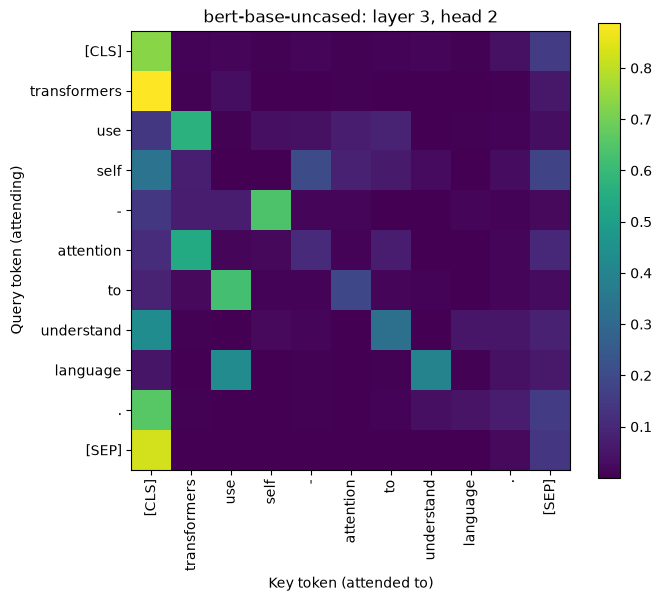

In [13]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(attention_l3_h2.numpy(), cmap="viridis")
ax.set_xticks(range(len(task_tokens)))
ax.set_xticklabels(task_tokens, rotation=90)
ax.set_yticks(range(len(task_tokens)))
ax.set_yticklabels(task_tokens)
ax.set_xlabel("Key token (attended to)")
ax.set_ylabel("Query token (attending)")
ax.set_title("bert-base-uncased: layer 3, head 2")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

**Step 9 - Task 4: what the rows and columns mean.**

**Answer.**

- **Rows are the query tokens:** the token that is "looking". Row *i* shows how token *i* spreads its attention when layer 3 builds its new representation.
- **Columns are the key tokens:** the tokens being looked at. Column *j* is token *j* as a source of information.
- **Each cell (i, j)** is the weight token *i* gives to token *j*. The matrix is 11 x 11 because the sentence becomes 11 tokens, including `[CLS]` and `[SEP]`.
- **Each row is a probability distribution:** it comes out of a softmax, so it adds up to 1. Step 7 confirms this for every row. Columns do not have to add up to 1.
- **The matrix is not symmetric:** `use` gives 0.569 to `transformers`, but `transformers` gives only 0.034 to `use`.

**What this head does on this sentence:**
- **Much of the weight goes to `[CLS]`:** for example `transformers` 0.889, `[SEP]` 0.828 and `.` 0.658. Heads often park attention on a special token when they have nothing useful to pick up.
- **The rest links words that belong together:** `-` attends to `self` (0.639), `to` to `use` (0.622), `use` to `transformers` (0.569), and `language` to `use` (0.429) and `understand` (0.398).